# *S. aureus*: local recombination and mutation rates, and hotspots

This notebook repeats the *Staphylococcus aureus* analysis of the paper (Section 3.3):

1. load the observed summary statistics of 1,982 core genes of 110 *S. aureus* genomes;
2. train NPE on 50,000 ClonalOrigin simulations on the *S. aureus* clonal genealogy;
3. sample the posterior of $(\rho_s, \theta_s, \ell)$ for every gene;
4. detect recombination and mutation hotspots with the ppDoG detector.

Run it from the `examples` folder.
The trained posterior is saved in `data/`, and later runs load it instead of training again.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from bacnpe.summary_stats import STAT_NAMES
from bacnpe.npe import LeaveLengthOut_NN, train_npe, save_npe, load_npe, sample_posteriors
from bacnpe.detection import detect_hotspots, save_hotspot_tables

warnings.filterwarnings("ignore", category=UserWarning)

DATA = Path("data")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

c:\Users\u2008181\bacnpe\.bacnpe_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load observed data

One row per core gene. Positions refer to the reference genome *S. aureus* MRSA252.

In [2]:
x_obs_info_table = pd.read_csv(DATA / "staph_core_gene_info.csv", index_col=0)
x_obs_info_table.head()

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_MRSA252,Start_pos_MRSA252,End_pos_MRSA252
Gene_ID,,,,,,,
dnaA,1362,517,1878,True,1362,517,1878
dnaN,1134,2156,3289,True,1134,2156,3289
SAR0003,246,3670,3915,True,246,3670,3915
recF,1113,3912,5024,True,1113,3912,5024
gyrB,1932,5037,6968,True,1932,5037,6968


The observed statistics for each core gene.

In [3]:
x_obs = np.loadtxt(DATA / "staph_core_gene_summary_stats.csv", delimiter=",")
print(x_obs.shape)
print("Lengths match the gene table:", np.allclose(x_obs[:, -1], x_obs_info_table["Gene_Length"]))
pd.DataFrame(x_obs, columns=STAT_NAMES).head()

(1982, 30)
Lengths match the gene table: True


,D_near_sum,D_far_sum,D_prime_near_sum,D_prime_far_sum,r2_near_sum,r2_far_sum,g4_near_sum,g4_far_sum,D_near_mean,D_far_mean,...,wakeley_pi2,tajima_D,wall_B,wall_Q,hudson_Rm,kelly_ZnS,r2_decay_a,r2_decay_b,r2_decay_c,L
0,7.260992,1.742397,460.045044,164.503327,36.711161,9.595627,9.0,3.0,0.015615,0.010560,...,10.220009,-0.503266,0.028571,0.055556,4.0,0.073503,0.935503,19.352324,0.064497,1362.0
1,5.145702,0.824876,775.783980,120.000000,48.881814,7.015775,12.0,0.0,0.006572,0.006874,...,6.967684,-1.285856,0.119048,0.209302,3.0,0.061902,0.268243,15.627929,0.065391,1134.0
2,0.004463,0.000000,10.000000,0.000000,0.004865,0.000000,0.0,0.0,0.000446,0.000000,...,0.201555,-1.560774,0.000000,0.000000,0.0,0.000486,-0.000447,17.976279,0.000531,246.0
3,1.534959,0.203636,360.239170,101.194139,14.712357,1.389081,5.0,2.0,0.004229,0.001996,...,2.980656,-1.694897,0.033333,0.064516,2.0,0.034627,-0.037427,0.384971,0.028426,1113.0
4,13.946281,2.480000,1676.565363,365.351926,102.650065,10.595015,45.0,19.0,0.008199,0.006544,...,16.084094,-1.115822,0.078125,0.123077,8.0,0.054445,-0.041470,12.120227,0.041812,1932.0


### Delete observations with no signal

Genes without segregating sites carry almost no information about the rates, and their summary
statistics are undefined (NaN), so they are removed here. Genes longer than 10,000 bp would be outside
the prior on $\ell$ (there are none in this dataset).

In [4]:
no_signal = x_obs[:, STAT_NAMES.index("prop_segregating_sites")] == 0
too_long = x_obs_info_table["Gene_Length"].to_numpy() > 10_000
keep = ~(no_signal | too_long)
print(f"No signal: {no_signal.sum()}, too long: {too_long.sum()}, kept: {keep.sum()} of {len(keep)}")

x_obs = x_obs[keep]
gene_info = x_obs_info_table[keep]

No signal: 18, too long: 0, kept: 1964 of 1982


## Load simulation data

50,000 simulations on the *S. aureus* clonal genealogy with $\delta = 454$ bp, using the priors
$\rho_s \sim U(0, 0.1)$, $\theta_s \sim U(0, 0.02)$ and $\ell \sim$ DiscreteUniform $\{20, \dots, 10000\}$.
`staph_theta.csv` holds the parameters $(\rho_s, \theta_s, \ell)$ and `staph_x.csv` the 30 statistics,
row by row. They can be generated with `bacnpe.parallel_sim` (see `01_simulate.py`).

In [5]:
theta = np.loadtxt(DATA / "staph_theta.csv", delimiter=",")
x = np.loadtxt(DATA / "staph_x.csv", delimiter=",")
print(theta.shape, x.shape)
print("Parameter ranges:", theta.min(axis=0), theta.max(axis=0))

(50000, 3) (50000, 30)
Parameter ranges: [1.47356412e-06 8.90106225e-07 2.00000000e+01] [9.99979148e-02 1.99994242e-02 9.99900000e+03]


## NPE

### Using all simulations

The configuration selected in the paper (Table S3):

- compression network: one hidden layer of 128 units, 2 learned features plus $\ell$;
- neural spline flow: 8 transforms, 30 hidden features, 5 bins;
- training: learning rate $10^{-4}$, batch size 100, early stopping after 20 epochs without improvement.

Simulations with NaN statistics are dropped before training.

In [6]:
seed = 100
save_path = DATA / "staph_trained_npe.pt"

if save_path.exists():
    posterior = load_npe(save_path)["posterior"]
else:
    torch.manual_seed(seed)
    embedding_net = LeaveLengthOut_NN(input_dim=30, num_hiddens=128, num_hidden_layers=1, num_outputs=2)
    result = train_npe(
        theta, x,
        seed=seed,
        embedding_net=embedding_net,
        model="nsf", hidden_features=30, num_transforms=8, num_bins=5,
        training_batch_size=100, learning_rate=1e-4,
        max_num_epochs=500, stop_after_epochs=20, clip_max_norm=None,
    )
    print(f"Dropped {result.settings['n_dropped']} simulations with NaN/inf statistics")
    save_npe(result, save_path)
    posterior = result.posterior

### Training and validation loss

Only available right after training (not when the posterior was loaded from file).

In [7]:
if "result" in globals():
    summary = result.inference.summary
    plt.figure(figsize=(8, 4))
    plt.plot(summary["training_loss"], label="Training loss")
    plt.plot(summary["validation_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.show()

### Plug in observation data to get posterior

`theta_post[g, m]` is posterior draw $m$ of $(\rho_s, \theta_s, \ell)$ for gene $g$.

In [8]:
num_posterior_samples = 1000
theta_post = sample_posteriors(posterior, x_obs, num_samples=num_posterior_samples, seed=seed)
theta_post.shape

Sampling posteriors: 100%|██████████| 1964/1964 [00:58<00:00, 33.58it/s]


(1964, 1000, 3)

As a check of the inference (Figure S6 of the paper), the inferred gene lengths should match the observed ones.

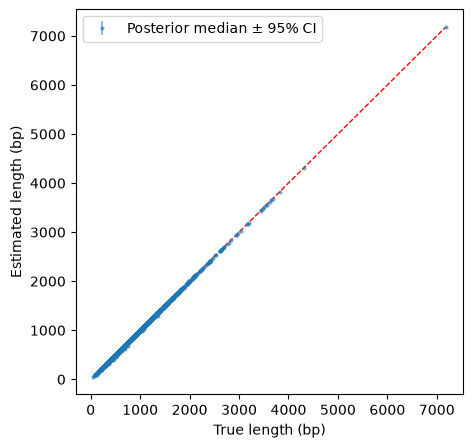

In [9]:
L_obs = x_obs[:, -1]
L_q = np.quantile(theta_post[:, :, 2], [0.025, 0.5, 0.975], axis=1)

plt.figure(figsize=(5, 5))
plt.errorbar(L_obs, L_q[1], yerr=[L_q[1] - L_q[0], L_q[2] - L_q[1]], fmt="o", ms=2, alpha=0.5,
             label="Posterior median ± 95% CI")
plt.plot([L_obs.min(), L_obs.max()], [L_obs.min(), L_obs.max()], "r--", lw=1)
plt.xlabel("True length (bp)")
plt.ylabel("Estimated length (bp)")
plt.legend()
plt.show()

## Detect hotspots

ppDoG settings of the paper for *S. aureus* (Table S1): narrow bandwidth 10 kb, broad bandwidth 1 Mb,
$\tau = 0.2$, probability threshold 0.9, and minimum fold enrichment 1.2 (recombination)
and 40 (mutation). Genes are placed at their start positions on the 2,902,619 bp chromosome.

In [10]:
gene_starts = gene_info["Start_pos_MRSA252"].to_numpy()
gene_ends = gene_info["End_pos_MRSA252"].to_numpy()
chromosome_length_bp = 2_902_619

settings = dict(
    gene_ends=gene_ends,
    narrow_bandwidth_bp=10_000,
    broad_bandwidth_bp=1_000_000,
    probability_threshold=0.90,
    residual_log_sd=0.20,
    random_state=10,
    max_gap_bp=800_000,
)

### Recombination hotspots

Detected hotspot segments:
  2.90-0.02 Mb; 18 genes; peak P=0.965; peak enrichment=1.71x
  0.58-0.59 Mb; 18 genes; peak P=0.969; peak enrichment=2.35x
  2.17-2.19 Mb; 9 genes; peak P=0.961; peak enrichment=2.68x
  2.58-2.61 Mb; 26 genes; peak P=1.000; peak enrichment=7.13x
  2.64-2.66 Mb; 11 genes; peak P=0.996; peak enrichment=3.06x
  2.87-2.88 Mb; 10 genes; peak P=0.942; peak enrichment=1.69x


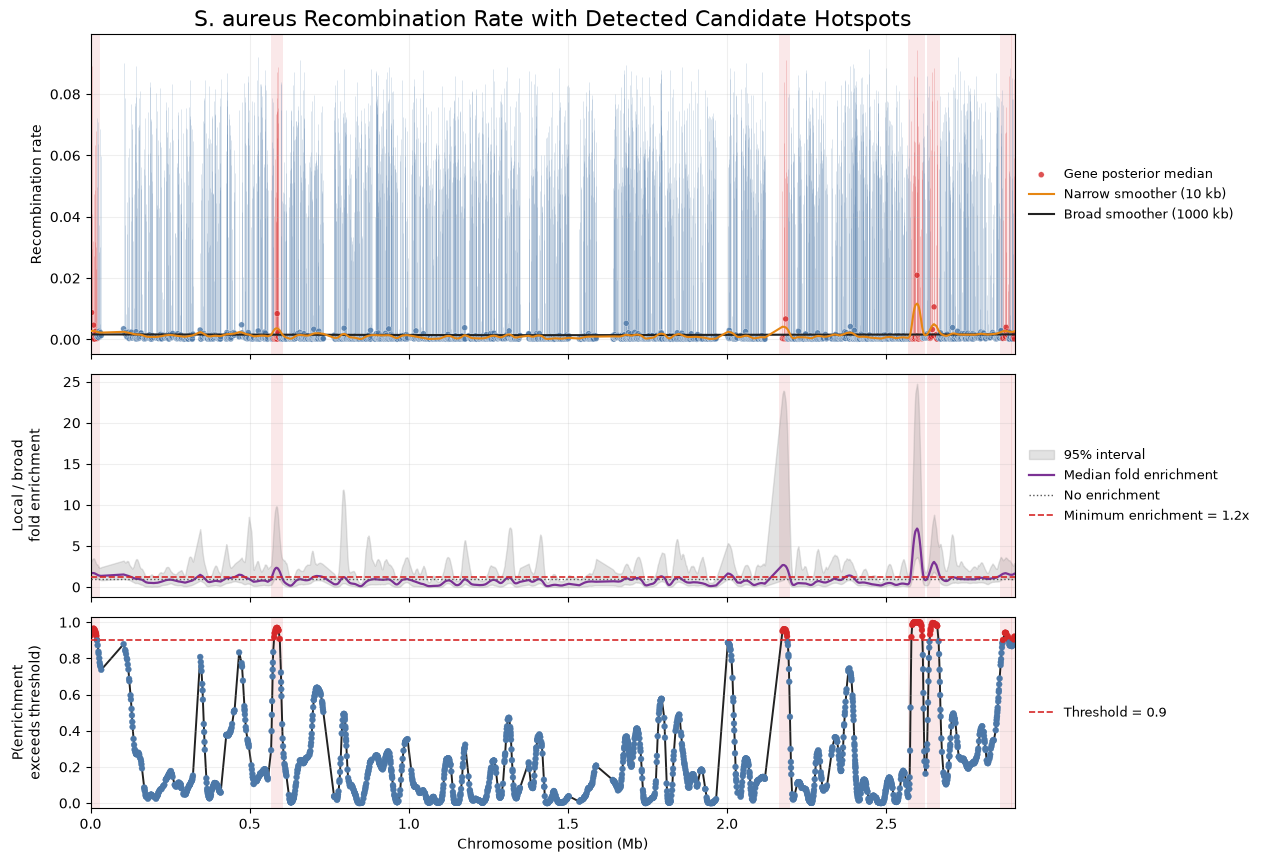

In [11]:
recomb = detect_hotspots(gene_starts, theta_post[:, :, 0], chromosome_length_bp,
                         min_fold_enrichment=1.2, **settings)
print(recomb.summary())

recomb.plot(
    rate_label="Recombination rate",
    title_text="S. aureus Recombination Rate with Detected Candidate Hotspots"
)
plt.show()

In [12]:
recomb_hotspots = recomb.to_dataframe()
recomb_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin
0,2900271.0,20720.0,18,0.965,1.711021,0.9420,True
1,576837.0,598142.0,18,0.969,2.351175,0.9635,False
2,2173762.0,2189640.0,9,0.961,2.683902,0.9580,False
3,2578730.0,2614375.0,26,1.000,7.127989,1.0000,False
4,2637343.0,2660657.0,11,0.996,3.060085,0.9820,False
5,2866243.0,2885569.0,10,0.942,1.685116,0.9325,False


Genes in the first recombination hotspot:

In [13]:
segments = recomb.segment_gene_indices()
gene_info.iloc[segments[0]] if segments else "No hotspot detected"

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_MRSA252,Start_pos_MRSA252,End_pos_MRSA252
Gene_ID,,,,,,,
SAR2798,1380,2900271,2901650,True,1380,2900271,2901650
rnpA,348,2901794,2902141,True,348,2901794,2902141
rpmH,138,2902268,2902405,True,138,2902268,2902405
dnaA,1362,517,1878,True,1362,517,1878
dnaN,1134,2156,3289,True,1134,2156,3289
SAR0003,246,3670,3915,True,246,3670,3915
recF,1113,3912,5024,True,1113,3912,5024
gyrB,1932,5037,6968,True,1932,5037,6968
gyrA,2661,7005,9665,True,2661,7005,9665


### Mutation hotspots

Detected hotspot segments:
  0.10-0.12 Mb; 10 genes; peak P=1.000; peak enrichment=55.66x
  0.45-0.48 Mb; 8 genes; peak P=1.000; peak enrichment=59.07x
  1.93-1.97 Mb; 30 genes; peak P=1.000; peak enrichment=68.01x
  2.02-2.03 Mb; 6 genes; peak P=0.930; peak enrichment=46.47x
  2.17-2.19 Mb; 10 genes; peak P=0.997; peak enrichment=60.51x
  2.49-2.50 Mb; 10 genes; peak P=0.933; peak enrichment=46.62x
  2.52-2.53 Mb; 9 genes; peak P=0.972; peak enrichment=49.91x
  2.62-2.67 Mb; 25 genes; peak P=0.999; peak enrichment=55.90x
  2.78-2.79 Mb; 6 genes; peak P=0.931; peak enrichment=45.58x
  2.84-2.85 Mb; 8 genes; peak P=0.912; peak enrichment=44.24x


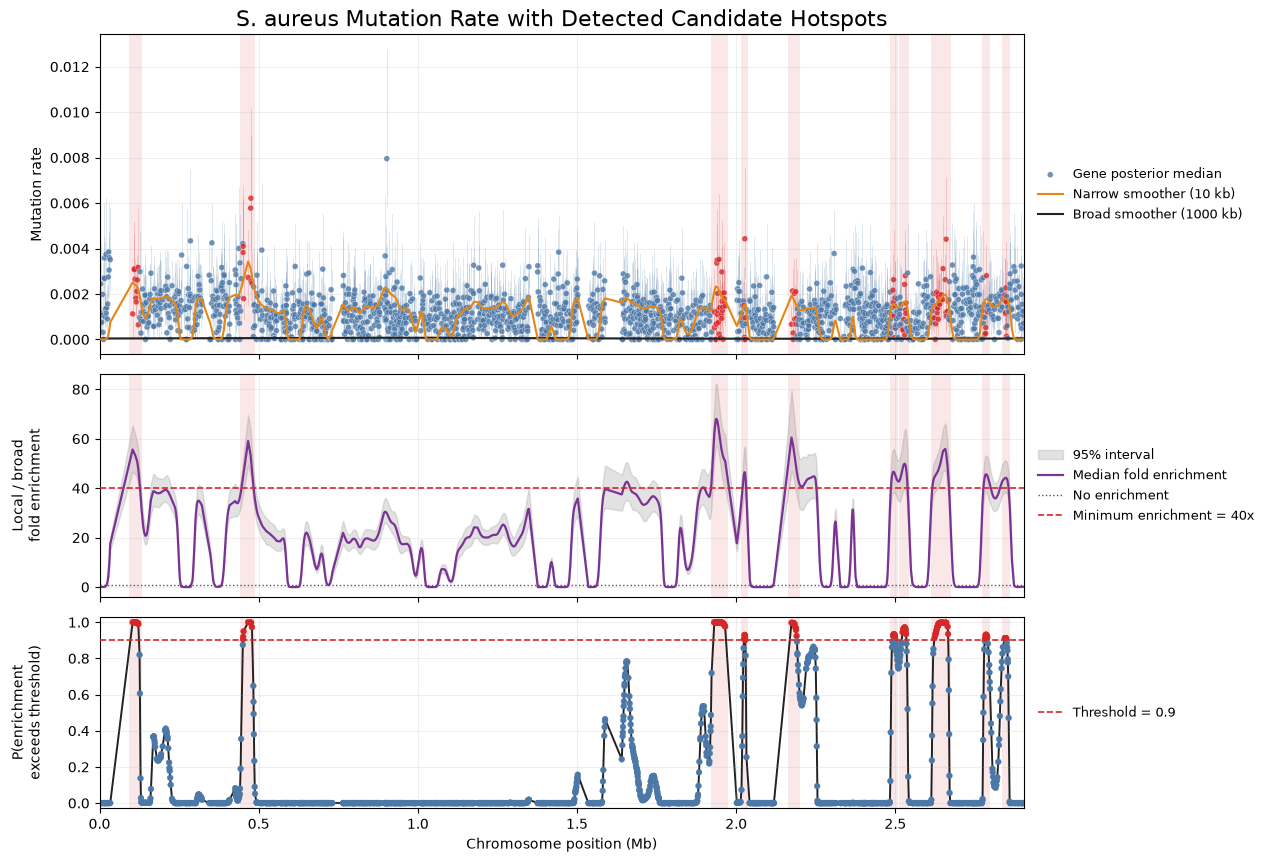

In [14]:
mutate = detect_hotspots(gene_starts, theta_post[:, :, 1], chromosome_length_bp,
                         min_fold_enrichment=40.0, **settings)
print(mutate.summary())

mutate.plot(
    rate_label="Mutation rate",
    title_text="S. aureus Mutation Rate with Detected Candidate Hotspots"
)
plt.show()

In [15]:
mutate_hotspots = mutate.to_dataframe()
mutate_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin
0,104041.0,123499.0,10,1.000,55.658148,0.9990,False
1,450865.0,480302.0,8,1.000,59.074087,0.9850,False
2,1931088.0,1965757.0,30,1.000,68.005348,0.9990,False
3,2024563.0,2029677.0,6,0.930,46.466851,0.9210,False
4,2173762.0,2190739.0,10,0.997,60.508689,0.9905,False
5,2492529.0,2500566.0,10,0.933,46.617637,0.9280,False
6,2522500.0,2534933.0,9,0.972,49.911977,0.9620,False
7,2622988.0,2667230.0,25,0.999,55.902146,0.9840,False
8,2781389.0,2790572.0,6,0.931,45.581133,0.9245,False
9,2843633.0,2849825.0,8,0.912,44.235260,0.9120,False


### Save the hotspot tables

One sheet per rate, as Table S5 of the paper.

In [16]:
save_hotspot_tables({"Recombination": recomb_hotspots, "Mutation": mutate_hotspots},
                    OUTPUT / "staph_hotspots.xlsx", overwrite=True)

WindowsPath('output/staph_hotspots.xlsx')